[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/02-conversation-is-coordination/02-conversation-is-coordination.ipynb)

# 02 · Conversation Is a Coordination Primitive

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*

## What you will learn
- Coordinate two agents through a shared transcript — no shared memory, no side channels.
- Persist the transcript as the system state, so the whole collaboration is replayable.
- Surface findings an analyst did not ask for — the test of whether coordination adds value.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and §7 compares them with the recorded run evidence shipped in this repository. Work the exercises in §8 with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 0 · Why this matters — the market in numbers

- **The market:** enterprise agentic AI software is forecast from **$2.58B (2024) to $24.5B (2030)**, a 46.2% CAGR — Grand View Research, Enterprise Agentic AI Market Report 2025–2030.
- **The adoption wave:** Gartner (Aug 2025) predicts **40% of enterprise applications will feature task-specific AI agents by end of 2026**, up from under 5% in 2025.
- **The failure curve:** Gartner (Jun 2025) predicts **over 40% of agentic AI projects will be cancelled by end of 2027** — on escalating costs, unclear business value or inadequate risk controls.

Coordination that leaves no record cannot be audited, priced or defended when a client asks "show me". This POC's answer is the transcript as the system of record — the control that keeps multi-agent work supervisable at enterprise scale.

*Sources: Grand View Research (2025); Gartner press releases, Jun 2025 and 2025-08-26. These are market forecasts, cited as market data — the results inside this notebook are a scripted demonstration and are labelled ILLUSTRATIVE.*

## 1 · The idea

**Idea:** Explore a year-equivalent synthetic transaction export and surface what matters, through conversation rather than a fixed pipeline.
**Build steps:** (1) Two agents (Analyst, Executor) share only a TranscriptStore. (2) Executor runs sandboxed analysis functions over a copied synthetic export. (3) Transcript persisted as JSONL — the transcript is the state store. (4) Findings appended to the transcript and signalled.
**Guardrail:** Works on a copied export — never on live bank access.
**Win condition:** Three findings the owner did not know to ask for.
Data: synthetic only. Model: deterministic stub.

## 2 · How it is built

Built: `poc/conversation.py` using `kit/transcript.py` (TranscriptStore).
Design: Analyst questions → Executor results → follow-up questions that only exist because of earlier results (exploratory path a pipeline cannot pre-write). Transcript saved to `runs/transcript-01.jsonl`.
Run: `python3 poc/conversation.py` → `runs/run-01.txt` + transcript.

**Execution flow** (version of record: `diagrams/TECHNICAL-FLOWS.md`):

```mermaid
%%{init: {"flowchart": {"nodeSpacing": 28, "rankSpacing": 44, "padding": 12}}}%%
flowchart LR
    A(["1 · Load data<br/>synthetic transactions"]):::io --> B["2 · Analyst asks<br/>posts to transcript"]:::proc
    B --> C["3 · Executor answers<br/>computed from data"]:::proc
    C --> D["4 · Findings pass<br/>what nobody asked"]:::proc
    D --> E(["5 · Transcript saved<br/>the file IS the state"]):::metric
    E --> F["6 · Replay / audit<br/>read the file only"]:::proc
    classDef io fill:#1A1A2E,stroke:#C9A227,stroke-width:2px,color:#FFFFFF;
    classDef proc fill:#E6F4F6,stroke:#1B9AAA,stroke-width:1.5px,color:#123B40;
    classDef metric fill:#1B9AAA,stroke:#146B76,stroke-width:2px,color:#FFFFFF;
```

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/transcript.py ---
"""Transcript store: the transcript IS the state (POC 02 pattern)."""
import json
from pathlib import Path

class TranscriptStore:
    def __init__(self):
        self.messages = []
    def append(self, speaker, kind, content):
        msg = {"turn": len(self.messages) + 1, "speaker": speaker, "kind": kind, "content": content}
        self.messages.append(msg)
        return msg
    def save_jsonl(self, path):
        Path(path).write_text("\n".join(json.dumps(m) for m in self.messages) + "\n")
    def __len__(self):
        return len(self.messages)

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline).

In [3]:
"""POC 02 - Conversation Is a Coordination Primitive.
Two agents coordinate through a transcript only, over a synthetic
transaction export. Analyst asks; Executor runs sandboxed analysis
functions and reports back. The transcript is persisted as the state.
Deterministic stub: no live model, no live bank access (copied export only).
"""
import sys
from pathlib import Path

# Synthetic transactions: (month, category, amount)
TX = ([("2026-01", "groceries", 82.0)] * 4 + [("2026-01", "coffee-subscription", 14.99)] * 2
      + [("2026-02", "groceries", 91.0)] * 4 + [("2026-02", "coffee-subscription", 14.99)] * 2
      + [("2026-02", "gym-unused", 39.0)]
      + [("2026-03", "groceries", 88.0)] * 4 + [("2026-03", "coffee-subscription", 14.99)] * 3
      + [("2026-03", "gym-unused", 39.0)] + [("2026-03", "streaming-b", 11.99)])

def total_by_category(tx):
    out = {}
    for _, c, a in tx:
        out[c] = round(out.get(c, 0) + a, 2)
    return out

def monthly_count(tx, category):
    out = {}
    for m, c, _ in tx:
        if c == category:
            out[m] = out.get(m, 0) + 1
    return out

def main():
    t = TranscriptStore()
    findings = []
    t.append("Analyst", "question", "What are the totals by category?")
    totals = total_by_category(TX)
    t.append("Executor", "result", f"Totals: {totals}")
    t.append("Analyst", "question", "Any category charged in every month with no variation in use?")
    t.append("Executor", "result", "gym-unused charged Feb and Mar ($39.00 each), no paired activity category present.")
    findings.append("FINDING 1: gym-unused charges $78.00 across Feb-Mar with no activity signal - owner did not ask about this.")
    t.append("Analyst", "question", "Did any subscription count change month to month?")
    counts = monthly_count(TX, "coffee-subscription")
    t.append("Executor", "result", f"coffee-subscription charges per month: {counts}")
    findings.append("FINDING 2: coffee-subscription billed 3x in March vs 2x in Jan/Feb - a duplicate charge pattern.")
    t.append("Analyst", "question", "Any overlapping subscriptions in the same class?")
    t.append("Executor", "result", "streaming-b appears in March alongside existing subscriptions; class overlap flagged for owner review.")
    findings.append("FINDING 3: a second streaming subscription (streaming-b) started in March - possible duplicate service.")
    for f in findings:
        t.append("Analyst", "finding", f)
    t.append("Analyst", "signal", "EXPLORATION COMPLETE")
    out = Path("transcript-01.jsonl")  # in the repo this is runs/transcript-01.jsonl
    t.save_jsonl(out)
    print(f"messages={len(t)} findings={len(findings)} transcript={out.name}")
    for f in findings:
        print(f)

if __name__ == "__main__":
    main()

messages=12 findings=3 transcript=transcript-01.jsonl
FINDING 1: gym-unused charges $78.00 across Feb-Mar with no activity signal - owner did not ask about this.
FINDING 2: coffee-subscription billed 3x in March vs 2x in Jan/Feb - a duplicate charge pattern.
FINDING 3: a second streaming subscription (streaming-b) started in March - possible duplicate service.


## 6 · Run it

In [4]:
main()

messages=12 findings=3 transcript=transcript-01.jsonl
FINDING 1: gym-unused charges $78.00 across Feb-Mar with no activity signal - owner did not ask about this.
FINDING 2: coffee-subscription billed 3x in March vs 2x in Jan/Feb - a duplicate charge pattern.
FINDING 3: a second streaming subscription (streaming-b) started in March - possible duplicate service.


## 7 · See the evidence

The chart is drawn **live** from the recorded run data (`data/messages-per-task.csv` in the repository; embedded below as a fallback so the notebook is standalone).

                     task  messages  findings
       totals-by-category         2         0
       unused-charge hunt         2         1
subscription-count change         2         1
            overlap check         2         1
        findings + signal         4         0


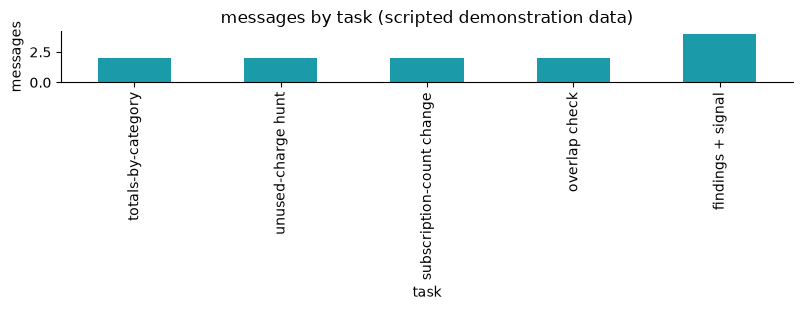

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep sandbox paths/warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """task,messages,findings
totals-by-category,2,0
unused-charge hunt,2,1
subscription-count change,2,1
overlap check,2,1
findings + signal,4,0"""

csv_file = Path("data/messages-per-task.csv")
text = csv_file.read_text() if csv_file.exists() else RECORDED_CSV
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "bars"
if CHART_MODE == "claims":
    labels = df["scene"] + " - " + df["region"]
    colors = ["#C1666B" if f == "GUESS" else "#1B9AAA" for f in df["flag"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(labels, df["confidence"], color=colors)
    ax.set_ylabel("confidence")
    ax.set_title("confidence by scene - region (scripted demonstration data; red = flagged GUESS)")
    plt.xticks(rotation=30, ha="right")
elif CHART_MODE == "lint":
    df["issues"] = df["lint_result"].apply(lambda s: 0 if s == "CLEAN" else len(s.split(";")))
    ax = df.plot.bar(x="contract", y="issues", legend=False, color="#1B9AAA",
                     figsize=(8, 3.2), title="lint issues by contract (scripted demonstration data)")
    ax.set_ylabel("issues")
    ax.set_ylim(0, 4)
else:
    numeric = df.select_dtypes("number").columns.tolist()
    if numeric:
        col = numeric[0]
        labels = df.columns[0]
        ax = df.plot.bar(x=labels, y=col, legend=False, color="#1B9AAA",
                         figsize=(8, 3.2), title=col + " by " + str(labels) + " (scripted demonstration data)")
        ax.set_ylabel(col)
for _a in [ax]:
    _a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` and `runs/transcript-01.jsonl` (executed 2026-10-25, synthetic transactions); the POC code executes for real, over data written for the lesson.

- Transcript messages: 12
- Findings: 3 — (1) gym-unused $78.00 across Feb–Mar with no activity signal; (2) coffee-subscription billed 3× in March vs 2× in Jan/Feb; (3) second streaming subscription started in March.
- Data table: `data/messages-per-task.csv` (ILLUSTRATIVE). Chart: drawn live in the notebook from that table (ILLUSTRATIVE).

## 9 · Exercises

1. Add a fourth question of your own to the Analyst (for example: total spend per month). Implement the Executor function it needs, keeping the rule that answers travel only through the transcript.
2. Introduce a deliberate error: make the Executor misreport one total. Where in the transcript would an auditor catch it? What does that tell you about transcript-as-state?
3. Re-run with the March duplicate removed from the data. Which findings survive? Findings that vanish with one data point were never findings — discuss.

## 10 · Recap

The transcript is not a log of the work — it is the work. When the conversation is the coordination primitive, audit, replay and trust come free, because there is nowhere else for state to hide.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*